# P5 · Đánh giá & tổng hợp — Bước 6–7–8

**Input (cell đầu tự nạp):** data/outputs/forecasts/*.parquet, common/segment_labels.parquet, data/processed/data_long.parquet

**Output (cell cuối tự lưu):** data/outputs/{metrics_by_model_segment,decision_table}.parquet

**Code mẫu tham khảo:** `notebooks/M5_reference.ipynb` phần **§7**.

> Chạy được **cell đầu** (thấy `✅ Input sẵn sàng`) = đủ input để làm phần của bạn. Code ở khu vực giữa. Cuối cùng chạy **cell lưu output**.

In [1]:
from pathlib import Path
def _need(p, hint):
    assert Path(p).exists(), f"❌ THIẾU INPUT: {p}\n   → {hint}"

import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from scipy import stats
_need("common/config.yaml", "clone repo")
_need("common/segment_labels.parquet", "clone repo (P1 đã tạo)")
_need("data/processed/data_long.parquet", "chạy P1.ipynb hoặc tải data_long P1 gửi vào data/processed/")
CFG = yaml.safe_load(open("common/config.yaml", encoding="utf-8"))
Q = CFG["quantiles"]; H = CFG["horizon"]; SP = CFG["split"]
seg = pd.read_parquet("common/segment_labels.parquet")
windows = pd.read_csv("common/rolling_windows.csv")
long = pd.read_parquet("data/processed/data_long.parquet")
FCDIR = Path("data/outputs/forecasts")
forecasts = {p.stem: pd.read_parquet(p) for p in sorted(FCDIR.glob("*.parquet"))}
assert forecasts, "❌ Chưa có forecast nào trong data/outputs/forecasts/ — chờ P3/P4 chạy + push rồi git pull."
print("✅ Input sẵn sàng — forecast từ:", list(forecasts.keys()))

✅ Input sẵn sàng — forecast từ: ['chronos_bolt', 'croston', 'lgbm', 'moirai_2', 'naive', 'sba', 'snaive', 'tsb', 'ttm']


## Phần code chính — Bước 6 · 7 · 8


| Bước | Nội dung | Cài đặt |
|---|---|---|
| 6 | Hiệu chuẩn chung | **Split-conformal** một phía cho *từng* mức quantile (CQR), residual chuẩn hoá theo scale MAE-naive của chuỗi, **Mondrian theo nhóm demand**. Tập hiệu chuẩn của cửa sổ *W* = forecast cho đoạn validation của *W* (d ∈ (train_end, val_end]) — chính là cửa sổ rolling liền trước, nên **không rò rỉ**. Cùng một thủ tục cho mọi model ⇒ "cùng một cây thước". |
| 7 | Metric | RMSSE (điểm, chính) · MASE (phụ) · **WSPL** (xác suất, chính; trọng số = doanh thu $ 28 ngày trước gốc) · SPL (phụ) · **coverage 50/67/95/99** (chính) + độ rộng dải 95 & bias để phân tích lỗi. Báo cáo **raw và calibrated**, theo **balanced** (mỗi nhóm ngang nhau) và **frequency-weighted** (theo tần suất thật trên 30.490 chuỗi). |
| 8 | Kiểm định + win rule | Mỗi (nhóm × metric × bản): **Diebold–Mariano** dạng panel (sai số chuẩn cluster theo chuỗi, Holm cho nhiều so sánh) + **MCB** (Koning et al. 2005, thứ hạng trung bình, critical distance Nemenyi). **"Thắng rõ"** ⇔ model tốt nhất hơn *mọi* model khác ở **mọi** cửa sổ (≥ 3) **và** DM p<0.05 **và** MCB có ý nghĩa. Ngược lại **"tương đương"** → chọn model **rẻ nhất** trong nhóm tương đương. |

Giả định về forecast đầu vào: forecast cho đoạn `[a, a+27]` được sinh từ gốc `a−1` (đúng như các cửa sổ không chồng lấn của `rolling_windows.csv`).

In [2]:
# ---------- 6.0 Tham số đánh giá (chốt trước khi xem kết quả) ----------
from scipy.stats import rankdata, studentized_range, norm

Q = [round(float(q), 3) for q in Q]
QI = {q: i for i, q in enumerate(Q)}
SEG_ORDER = ["smooth", "erratic", "intermittent", "lumpy"]
COV_PAIRS = [(0.25, 0.75, 50), (0.165, 0.835, 67), (0.025, 0.975, 95), (0.005, 0.995, 99)]
METRICS = {"RMSSE": "điểm (chính)", "MASE": "điểm (phụ)", "WSPL": "xác suất (chính)", "SPL": "xác suất (phụ)"}
ALPHA = 0.05          # mức ý nghĩa DM / MCB
MIN_WINDOWS = 3       # win rule: chênh phải sống qua >= 3 cửa sổ rolling-origin
MIN_COVERAGE = 0.99   # model phải có forecast đủ cho >= 99% (chuỗi × cửa sổ) mới vào so sánh chính
PRIMARY = ("calibrated", "WSPL")   # tiêu chí của decision_table (bảng 1 dòng / nhóm cho P2)
# chi phí vận hành tương đối (chỉ dùng để phân định khi "tương đương"; thấp = rẻ)
COST_RANK = {"naive": 0, "snaive": 0, "croston": 1, "sba": 1, "tsb": 1,
             "lgbm": 2, "ttm": 3, "chronos_bolt": 4, "moirai_2": 5}

ids = pd.Index(sorted(pd.read_csv("common/sample_ids.csv")["series_id"]))
SEG = seg.set_index("series_id")["segment"].reindex(ids).to_numpy()
POP_SHARE = seg["segment"].value_counts(normalize=True).reindex(SEG_ORDER)   # tần suất thật (30.490 chuỗi)
windows = windows.sort_values("test_start", ascending=False).reset_index(drop=True)
WIN = {r.window: dict(origin=int(r.test_start) - 1, test=int(r.test_start), cal=int(r.train_end) + 1)
       for r in windows.itertuples()}
print("Mẫu:", len(ids), "chuỗi |", pd.Series(SEG).value_counts().reindex(SEG_ORDER).to_dict())
print("Cửa sổ:", {w: f"test d{v['test']}-{v['test']+H-1}, hiệu chuẩn d{v['cal']}-{v['cal']+H-1}" for w, v in WIN.items()})
print("Tần suất thật:", POP_SHARE.round(3).to_dict())

Mẫu: 3474 chuỗi | {'smooth': 980, 'erratic': 494, 'intermittent': 1000, 'lumpy': 1000}
Cửa sổ: {'W1': 'test d1914-1941, hiệu chuẩn d1886-1913', 'W2': 'test d1886-1913, hiệu chuẩn d1858-1885', 'W3': 'test d1858-1885, hiệu chuẩn d1830-1857'}
Tần suất thật: {'smooth': 0.032, 'erratic': 0.016, 'intermittent': 0.757, 'lumpy': 0.194}


In [3]:
# ---------- 6.1 Ma trận actual / giá + scale & trọng số tại từng gốc (chỉ dùng dữ liệu <= gốc) ----------
D_MAX = int(SP["max_actual_day"])
lg = long[long.series_id.isin(ids)]
_mat = lambda col: (lg.pivot(index="series_id", columns="d_int", values=col)
                      .reindex(index=ids, columns=range(1, D_MAX + 1)).to_numpy(np.float64))
Y, PRICE = _mat("sales"), _mat("sell_price")          # cột j <-> d_(j+1)
assert not np.isnan(Y).any(), "data_long thiếu actual cho một số (chuỗi, ngày) trong mẫu"
del lg

def scales_at(origin):
    """Scale kiểu M5 trên insample d_1..d_origin, tính từ lần bán đầu tiên: s1 = MAE naive-1, s2 = MSE naive-1."""
    y = Y[:, :origin]
    nz = y > 0
    first = np.where(nz.any(1), nz.argmax(1), origin)
    d = np.diff(y, axis=1)
    valid = np.arange(origin - 1)[None, :] >= first[:, None]
    n = np.maximum(valid.sum(1), 1)
    s1 = (np.abs(d) * valid).sum(1) / n
    s2 = (d ** 2 * valid).sum(1) / n
    s1[s1 <= 0] = np.nan; s2[s2 <= 0] = np.nan
    return s1, s2

def dollar_weight(origin):
    """Trọng số WSPL = doanh thu $ của 28 ngày cuối trước gốc (kiểu M5 Uncertainty)."""
    sl = slice(origin - H, origin)
    return np.nansum(Y[:, sl] * np.nan_to_num(PRICE[:, sl]), axis=1)

SCALE = {w: scales_at(v["origin"]) for w, v in WIN.items()}
WEIGHT = {w: dollar_weight(v["origin"]) for w, v in WIN.items()}
for w in WIN:
    print(w, "| chuỗi không có scale (chưa từng bán/không đổi trước gốc):", int(np.isnan(SCALE[w][0]).sum()))

W1 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0
W2 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0
W3 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0


In [4]:
# ---------- 6.2 Forecast -> tensor (chuỗi × 28 ngày × 9 quantile) cho từng đoạn 28 ngày ----------
BLOCKS = sorted({v["test"] for v in WIN.values()} | {v["cal"] for v in WIN.values()})

def to_blocks(df):
    df = df[df.series_id.isin(ids)]
    si = ids.get_indexer(df.series_id)
    qi = df.quantile_level.round(3).map(QI).fillna(-1).astype(int).to_numpy()
    d = df.d_int.to_numpy(); v = df.value.to_numpy(np.float64)
    out = {}
    for b in BLOCKS:
        m = (d >= b) & (d < b + H) & (qi >= 0)
        if not m.any():
            continue
        a = np.full((len(ids), H, len(Q)), np.nan)
        a[si[m], d[m] - b, qi[m]] = v[m]
        out[b] = a
    return out

def tidy(a):
    """Ép về miền hợp lệ: không âm + sắp lại quantile (rearrangement) nếu bị crossing."""
    return np.sort(np.clip(a, 0, None), axis=2)

FC, cross_rate, avail = {}, {}, []
for name, df in forecasts.items():
    blocks = to_blocks(df)
    cross_rate[name] = np.nanmean([(np.diff(a, axis=2) < -1e-9).any(2)[~np.isnan(a).any(2)].mean()
                                   for a in blocks.values()]) if blocks else np.nan
    FC[name] = {b: tidy(a) for b, a in blocks.items()}
    for w, v in WIN.items():
        for role in ("test", "cal"):
            a = blocks.get(v[role])
            frac = 0.0 if a is None else float((~np.isnan(a).any((1, 2))).mean())
            avail.append(dict(model=name, window=w, role=role, frac_series=frac))

avail = pd.DataFrame(avail)
avail_tab = avail.pivot_table(index="model", columns=["role", "window"], values="frac_series")
print("Tỷ lệ chuỗi mẫu có forecast đủ 28×9 (test = chấm điểm, cal = hiệu chuẩn):")
display(avail_tab.round(3))
print("Tỷ lệ (chuỗi,ngày) bị quantile crossing trước khi sắp lại:", {k: round(v, 4) for k, v in cross_rate.items()})

test_ok = avail[avail.role == "test"].groupby("model").frac_series.min()
MODELS = sorted(test_ok[test_ok >= MIN_COVERAGE].index)
EXCLUDED = sorted(set(forecasts) - set(MODELS))
print("✅ Model vào so sánh chính:", MODELS)
if EXCLUDED:
    print("⚠ Bị loại (thiếu chuỗi/cửa sổ — cần P3/P4 chạy đủ 3 cửa sổ trên toàn mẫu):", EXCLUDED)

Tỷ lệ chuỗi mẫu có forecast đủ 28×9 (test = chấm điểm, cal = hiệu chuẩn):


role          cal             test          
window         W1   W2   W3     W1   W2   W3
model                                       
chronos_bolt  1.0  1.0  0.0  1.000  1.0  1.0
croston       0.0  0.0  0.0  0.204  0.0  0.0
lgbm          0.0  0.0  0.0  0.204  0.0  0.0
moirai_2      1.0  1.0  0.0  1.000  1.0  1.0
naive         0.0  0.0  0.0  0.204  0.0  0.0
sba           0.0  0.0  0.0  0.204  0.0  0.0
snaive        0.0  0.0  0.0  0.204  0.0  0.0
tsb           0.0  0.0  0.0  0.204  0.0  0.0
ttm           1.0  1.0  0.0  1.000  1.0  1.0

Tỷ lệ (chuỗi,ngày) bị quantile crossing trước khi sắp lại: {'chronos_bolt': np.float64(0.0), 'croston': np.float64(0.0), 'lgbm': np.float64(0.0), 'moirai_2': np.float64(0.0), 'naive': np.float64(0.0), 'sba': np.float64(0.0), 'snaive': np.float64(0.0), 'tsb': np.float64(0.0), 'ttm': np.float64(0.0)}
✅ Model vào so sánh chính: ['chronos_bolt', 'moirai_2', 'ttm']
⚠ Bị loại (thiếu chuỗi/cửa sổ — cần P3/P4 chạy đủ 3 cửa sổ trên toàn mẫu): ['croston', 'lgbm', 'naive', 'sba', 'snaive', 'tsb']


### Bước 6 — Hiệu chuẩn chung (split-conformal)

Với mỗi model, cửa sổ *W*, nhóm *g* và mức quantile τ: lấy residual chuẩn hoá trên tập hiệu chuẩn
$r = (y - \hat q_\tau)/s_i$, rồi dịch quantile test một lượng $\delta_{g,\tau}\cdot s_i$, với $\delta$ là thống kê thứ tự
$\lceil (n+1)\tau \rceil$ (τ ≥ 0.5) hoặc $\lfloor (n+1)\tau \rfloor$ (τ < 0.5) của $r$ — bảo đảm coverage biên hữu hạn mẫu (Romano et al., 2019).
Không cần biết model sinh quantile thế nào (native / kẹp đuôi / bọc NB) → so sánh công bằng.
Scale $s_i$ lấy tại gốc test (chỉ dữ liệu ≤ gốc). Cửa sổ nào **chưa có** forecast cho đoạn hiệu chuẩn → không có bản calibrated (ghi rõ trong bảng).

In [5]:
# ---------- 6.3 Split-conformal: offset theo (nhóm × mức quantile) ----------
def conformal_offsets(cal, y, s):
    r = (y[:, :, None] - cal) / s[:, None, None]
    ok_series = np.isfinite(s) & ~np.isnan(cal).any((1, 2))
    off = {}
    for g in SEG_ORDER:
        R = np.sort(r[ok_series & (SEG == g)].reshape(-1, len(Q)), axis=0)
        n = len(R)
        if n == 0:
            off[g] = np.zeros(len(Q)); continue
        k = np.array([np.ceil((n + 1) * t) if t >= 0.5 else np.floor((n + 1) * t) for t in Q])
        k = np.clip(k, 1, n).astype(int) - 1
        off[g] = R[k, np.arange(len(Q))]
    return off

def apply_offsets(a, off, s):
    shift = np.stack([off[g] for g in SEG]) * np.nan_to_num(s)[:, None]   # (n, 9)
    return tidy(a + shift[:, None, :])

CAL, OFFSETS = {}, []
for name in MODELS:
    for w, v in WIN.items():
        cal = FC[name].get(v["cal"])
        if cal is None or (~np.isnan(cal).any((1, 2))).mean() < MIN_COVERAGE:
            continue
        y_cal = Y[:, v["cal"] - 1: v["cal"] - 1 + H]
        off = conformal_offsets(cal, y_cal, SCALE[w][0])
        CAL[(name, w)] = apply_offsets(FC[name][v["test"]], off, SCALE[w][0])
        OFFSETS += [dict(model=name, window=w, segment=g, quantile_level=q, offset_scaled=float(off[g][j]))
                    for g in SEG_ORDER for j, q in enumerate(Q)]
calibration_offsets = pd.DataFrame(OFFSETS)
# một cửa sổ chỉ có bản calibrated khi MỌI model đều hiệu chuẩn được (để so trên cùng tập)
cal_windows = sorted(w for w in WIN if all((m, w) in CAL for m in MODELS))
print("Cửa sổ có bản calibrated (đủ mọi model):", cal_windows)
missing_cal = sorted({m for m in MODELS for w in WIN if (m, w) not in CAL})
if missing_cal:
    print("  model thiếu forecast đoạn hiệu chuẩn ở ít nhất 1 cửa sổ:", missing_cal)
if len(cal_windows) < len(WIN):
    print(f"⚠ {sorted(set(WIN) - set(cal_windows))} chưa có forecast cho đoạn hiệu chuẩn "
          f"(d{min(v['cal'] for v in WIN.values())}-{min(v['cal'] for v in WIN.values())+H-1}) → "
          "bản calibrated chỉ có", len(cal_windows), "cửa sổ; theo win rule chưa thể 'thắng rõ'.")

Cửa sổ có bản calibrated (đủ mọi model): ['W1', 'W2']
  model thiếu forecast đoạn hiệu chuẩn ở ít nhất 1 cửa sổ: ['chronos_bolt', 'moirai_2', 'ttm']
⚠ ['W3'] chưa có forecast cho đoạn hiệu chuẩn (d1830-1857) → bản calibrated chỉ có 2 cửa sổ; theo win rule chưa thể 'thắng rõ'.


### Bước 7 — Chấm metric theo chuỗi rồi tổng hợp

- Theo chuỗi: RMSSE/MASE dùng P50; SPL = trung bình pinball 9 mức / s1; coverage của 4 dải đối xứng; độ rộng dải 95 (chuẩn hoá); bias = (P50 − actual)/s1.
- Tập so sánh: trong mỗi (bản, cửa sổ), chỉ giữ chuỗi mà **mọi** model đều có forecast và có scale ⇒ các model được chấm trên **cùng** một tập.
- Tổng hợp nhóm: trung bình chuỗi (WSPL: trung bình có trọng số $). `window = ALL` = trung bình các cửa sổ.
  `ALL (balanced)` = trung bình 4 nhóm ngang nhau; `ALL (frequency-weighted)` = trọng số theo tần suất thật của nhóm trên 30.490 chuỗi.

In [6]:
# ---------- 7.1 Chấm theo chuỗi ----------
TAU = np.array(Q)

def score(F, y, s1, s2):
    q50 = F[:, :, QI[0.5]]
    e = y - q50
    diff = y[:, :, None] - F
    out = dict(RMSSE=np.sqrt((e ** 2).mean(1) / s2),
               MASE=np.abs(e).mean(1) / s1,
               SPL=np.maximum(TAU * diff, (TAU - 1) * diff).mean(1).mean(1) / s1)
    for lo, hi, nom in COV_PAIRS:
        out[f"cov{nom}"] = ((y >= F[:, :, QI[lo]]) & (y <= F[:, :, QI[hi]])).mean(1)
    # miss một phía của dải 95: với dữ liệu đếm có sàn 0, nếu P2.5 = 0 thì không thể miss phía dưới
    out["miss_lo95"] = (y < F[:, :, QI[0.025]]).mean(1)
    out["miss_hi95"] = (y > F[:, :, QI[0.975]]).mean(1)
    out["width95"] = (F[:, :, QI[0.975]] - F[:, :, QI[0.025]]).mean(1) / s1
    out["bias"] = (q50 - y).mean(1) / s1
    out["over_rate"] = (q50 > y).mean(1)
    out["under_rate"] = (q50 < y).mean(1)
    return out

rows = []
for version in ("raw", "calibrated"):
    for w, v in WIN.items():
        get = (lambda m: FC[m].get(v["test"])) if version == "raw" else (lambda m: CAL.get((m, w)))
        arrs = {m: get(m) for m in MODELS}
        if any(a is None for a in arrs.values()):
            continue
        s1, s2 = SCALE[w]
        ok = np.isfinite(s1) & np.isfinite(s2)
        for a in arrs.values():
            ok &= ~np.isnan(a).any((1, 2))
        y = Y[ok, v["test"] - 1: v["test"] - 1 + H]
        for m, a in arrs.items():
            sc = score(a[ok], y, s1[ok], s2[ok])
            rows.append(pd.DataFrame(dict(version=version, window=w, model=m, series_id=ids[ok],
                                          segment=SEG[ok], weight=WEIGHT[w][ok], **sc)))
per_series = pd.concat(rows, ignore_index=True)
print("per_series:", per_series.shape)
display(per_series.groupby(["version", "window"]).series_id.nunique().unstack().rename_axis(None))

per_series: (52110, 19)


window,W1,W2,W3
calibrated,3474.0,3474.0,NaN
raw,3474.0,3474.0,3474.0


In [7]:
# ---------- 7.2 Tổng hợp model × nhóm (theo cửa sổ + ALL), balanced & frequency-weighted ----------
COV_COLS = [f"cov{n}" for _, _, n in COV_PAIRS]
MEAN_COLS = ["RMSSE", "MASE", "SPL", *COV_COLS, "miss_lo95", "miss_hi95", "width95", "bias", "over_rate", "under_rate"]

def _agg(g):
    out = g[MEAN_COLS].mean()
    out["WSPL"] = np.average(g.SPL, weights=g.weight) if g.weight.sum() > 0 else np.nan
    out["n_series"] = len(g)
    return out

by_win = (per_series.groupby(["version", "window", "model", "segment"]).apply(_agg, include_groups=False)
          .reset_index())
all_win = (by_win.groupby(["version", "model", "segment"])
           .agg(**{c: (c, "mean") for c in MEAN_COLS + ["WSPL"]}, n_series=("n_series", "max"),
                n_windows=("window", "nunique"))
           .reset_index().assign(window="ALL"))
by_win["n_windows"] = 1
seg_tab = pd.concat([all_win, by_win], ignore_index=True)

def _overall(g, label, wts):
    g = g.set_index("segment").reindex(SEG_ORDER)
    out = {c: float(np.average(g[c], weights=wts)) for c in MEAN_COLS + ["WSPL"]}
    out.update(segment=label, n_series=int(g.n_series.sum()), n_windows=int(g.n_windows.max()))
    return pd.Series(out)

ov = []
for label, wts in [("ALL (balanced)", np.ones(4) / 4), ("ALL (frequency-weighted)", POP_SHARE.to_numpy())]:
    ov.append(seg_tab.groupby(["version", "window", "model"]).apply(lambda g: _overall(g, label, wts),
                                                                 include_groups=False).reset_index())
metrics_table = pd.concat([seg_tab, *ov], ignore_index=True)
metrics_table["cov_gap"] = np.mean([np.abs(metrics_table[f"cov{n}"] - n / 100) for _, _, n in COV_PAIRS], axis=0)
COLS_OUT = ["version", "window", "model", "segment", "n_series", "n_windows", "RMSSE", "MASE", "SPL", "WSPL",
            *COV_COLS, "cov_gap", "miss_lo95", "miss_hi95", "width95", "bias", "over_rate", "under_rate"]
SEG_ALL = SEG_ORDER + ["ALL (balanced)", "ALL (frequency-weighted)"]
metrics_table = (metrics_table[COLS_OUT]
                 .assign(segment=lambda d: pd.Categorical(d.segment, SEG_ALL, ordered=True))
                 .sort_values(["version", "window", "segment", "model"]).reset_index(drop=True))
metrics_table["segment"] = metrics_table.segment.astype(str)

def show(version, col, window="ALL"):
    t = (metrics_table.query("version == @version and window == @window")
         .pivot(index="model", columns="segment", values=col)[SEG_ALL])
    print(f"=== {col} · {version} · window={window} ==="); display(t.round(3))

for col in ["RMSSE", "WSPL", "cov95"]:
    for version in ("raw", "calibrated"):
        show(version, col)

=== RMSSE · raw · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.768,0.717,0.818,0.765,0.767,0.804
moirai_2,0.760,0.692,0.816,0.749,0.754,0.799
ttm,0.803,0.760,0.860,0.815,0.810,0.848


=== RMSSE · calibrated · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.758,0.703,0.831,0.767,0.765,0.814
moirai_2,0.735,0.669,0.827,0.750,0.746,0.807
ttm,0.797,0.746,0.873,0.820,0.809,0.858


=== WSPL · raw · window=ALL ===


...

segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.208,0.259,0.287,0.331,0.271,0.293
moirai_2,0.205,0.244,0.269,0.308,0.257,0.274
ttm,0.223,0.314,0.322,0.369,0.307,0.328


=== cov95 · raw · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.788,0.780,0.717,0.742,0.757,0.725
moirai_2,0.810,0.804,0.690,0.727,0.758,0.703
ttm,0.966,0.978,0.980,0.976,0.975,0.979


=== cov95 · calibrated · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.951,0.947,0.950,0.950,0.950,0.950
moirai_2,0.953,0.955,0.949,0.950,0.952,0.950
ttm,0.972,0.973,0.980,0.976,0.975,0.979


### Hiệu chuẩn: coverage danh nghĩa vs thực tế (raw → calibrated)

Mỗi ô: model × nhóm. Đường chéo = hiệu chuẩn hoàn hảo; dưới đường chéo = dải quá hẹp (tự tin thừa).

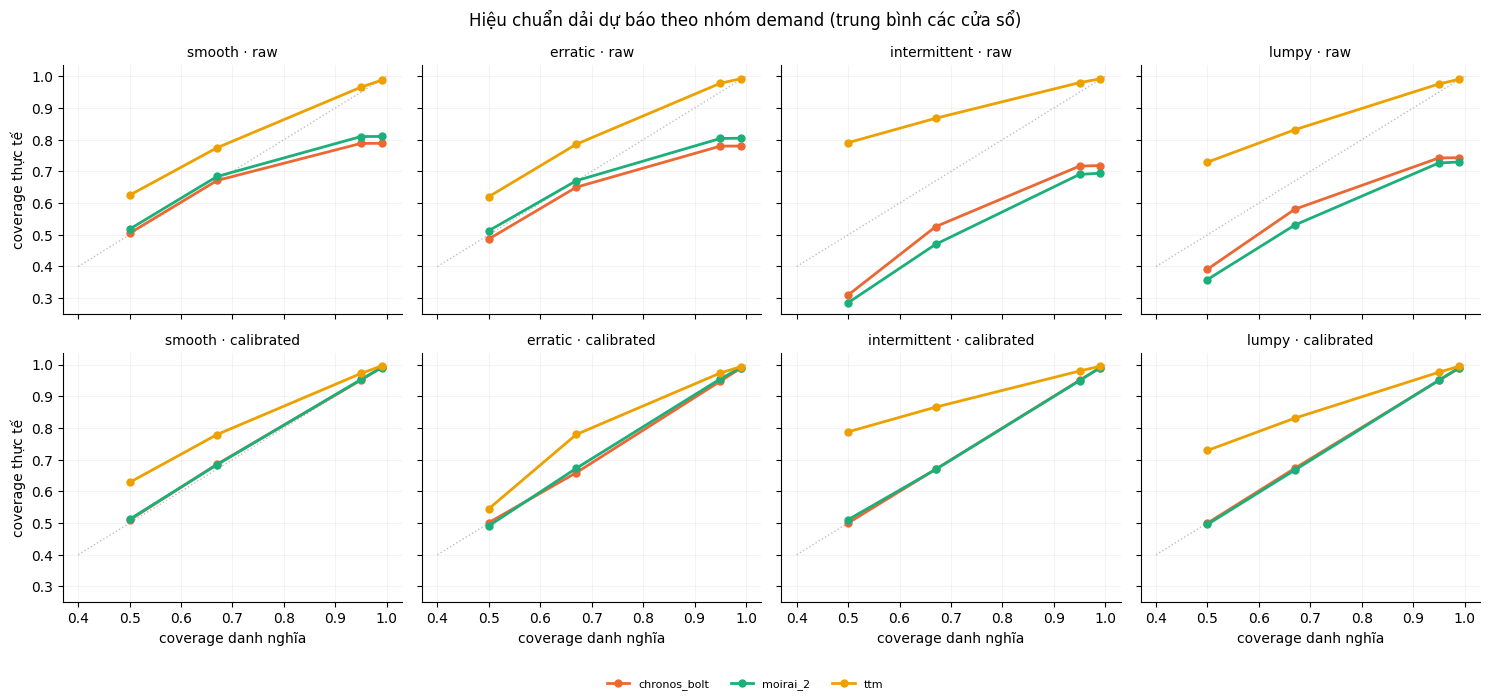

In [8]:
# ---------- 7.3 Reliability: coverage thực tế vs danh nghĩa ----------
NOM = [n / 100 for _, _, n in COV_PAIRS]
mt = metrics_table.query("window == 'ALL' and segment in @SEG_ORDER")
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
# màu cố định theo model (màu đi theo thực thể, không theo thứ hạng); nét đứt = họ cổ điển
COLOR = {"lgbm": "#2a78d6", "chronos_bolt": "#eb6834", "moirai_2": "#1baf7a", "ttm": "#eda100",
         "tsb": "#e87ba4", "sba": "#008300", "croston": "#4a3aa7", "snaive": "#e34948", "naive": "#8a8a85"}
STYLE = {m: "--" for m in ["naive", "snaive", "croston", "sba", "tsb"]}
for r, version in enumerate(("raw", "calibrated")):
    for c, g in enumerate(SEG_ORDER):
        ax = axes[r, c]
        ax.plot([0.4, 1], [0.4, 1], color="0.75", lw=1, ls=":")
        sub = mt.query("version == @version and segment == @g").set_index("model")
        for k, m in enumerate(MODELS):
            if m in sub.index:
                ax.plot(NOM, sub.loc[m, COV_COLS].to_numpy(float), marker="o", ms=5, lw=2,
                        ls=STYLE.get(m, "-"), color=COLOR.get(m, "#5f5e5a"), label=m)
        ax.set_title(f"{g} · {version}", fontsize=10)
        ax.grid(alpha=0.15); ax.spines[["top", "right"]].set_visible(False)
        if c == 0: ax.set_ylabel("coverage thực tế")
        if r == 1: ax.set_xlabel("coverage danh nghĩa")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=len(MODELS), fontsize=8, frameon=False)
fig.suptitle("Hiệu chuẩn dải dự báo theo nhóm demand (trung bình các cửa sổ)")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Đọc coverage sau hiệu chuẩn.** Conformal hiệu chuẩn *từng mức quantile một phía* (P(y ≤ q′_τ) ≈ τ). Với dữ liệu đếm có sàn 0,
khi P2.5 = 0 thì không thể "miss phía dưới" ⇒ coverage dải 95% hội tụ về ~0.975 chứ không phải 0.95 (xem `miss_lo95` / `miss_hi95`).
Đây là tính chất của dữ liệu gián đoạn, không phải lỗi hiệu chuẩn: phía trên (phía quyết định tồn kho) vẫn đúng mức danh nghĩa.

### Bước 8 — Kiểm định DM + MCB và win rule

Với mỗi (bản × nhóm × metric), đơn vị quan sát = (chuỗi, cửa sổ):
- **best** = model có metric tổng hợp thấp nhất (WSPL: trọng số $ chuẩn hoá trong từng cửa sổ).
- **DM (panel)**: chênh loss $d = L_m - L_{best}$, trung bình (có trọng số với WSPL), sai số chuẩn **cluster theo chuỗi** (các cửa sổ của cùng chuỗi không độc lập); p hai phía, hiệu chỉnh **Holm** trên k−1 so sánh.
- **MCB**: xếp hạng các model trong từng đơn vị, hạng trung bình; model *m* khác *best* có ý nghĩa nếu hạng chênh > CD = $q_{\alpha,k,\infty}/\sqrt{2}\cdot\sqrt{k(k+1)/(6N)}$.
- **Cửa sổ**: best phải tốt hơn *m* trong **từng** cửa sổ, và số cửa sổ ≥ 3.
- *m* "thua rõ" ⇔ cả ba điều kiện. Best **"thắng rõ"** ⇔ mọi *m* đều thua rõ. Ngược lại **"tương đương"** với các model không thua rõ → khuyến nghị model **rẻ nhất** trong nhóm tương đương.

*Hạn chế ghi nhận:* DM coi các chuỗi độc lập với nhau (cùng cửa hàng/ngày có thể tương quan) → p-value có thể hơi lạc quan; vì vậy win rule đòi **đồng thời** DM, MCB và tính ổn định qua cửa sổ.

In [9]:
# ---------- 8.1 DM + MCB + win rule ----------
def test_group(df, metric):
    loss_col = "SPL" if metric == "WSPL" else metric
    L = df.pivot_table(index=["series_id", "window"], columns="model", values=loss_col).dropna()
    models = list(L.columns)
    if metric == "WSPL":
        w = df.drop_duplicates(["series_id", "window"]).set_index(["series_id", "window"]).weight.reindex(L.index)
        w = w / w.groupby(level="window").transform("sum")
    else:
        w = pd.Series(1.0, index=L.index)
    w = w.fillna(0)
    n_win = L.index.get_level_values("window").nunique()
    # giá trị tổng hợp (trung bình các cửa sổ) + theo từng cửa sổ
    per_win = L.mul(w, axis=0).groupby(level="window").sum().div(w.groupby(level="window").sum(), axis=0)
    agg = per_win.mean()
    best = agg.idxmin()
    # MCB
    k, N = len(models), len(L)
    ranks = pd.Series(rankdata(L.to_numpy(), axis=1).mean(0), index=models)
    cd = studentized_range.ppf(1 - ALPHA, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * N)) if k > 1 else np.nan
    # DM panel, cluster theo chuỗi
    sid = L.index.get_level_values("series_id")
    res = []
    for m in models:
        if m == best:
            continue
        d = (L[m] - L[best]).to_numpy()
        ww = w.to_numpy()
        est = np.sum(ww * d) / np.sum(ww)
        u = pd.Series(ww * (d - est)).groupby(sid).sum().to_numpy()
        se = np.sqrt(np.sum(u ** 2)) / np.sum(ww)
        z = est / se if se > 0 else (np.inf if est > 0 else 0.0)
        res.append(dict(model=m, value=agg[m], diff_pct=100 * (agg[m] - agg[best]) / agg[best],
                        dm_stat=z, p_dm=2 * norm.sf(abs(z)), mcb_rank_diff=ranks[m] - ranks[best],
                        better_all_windows=bool((per_win[best] < per_win[m]).all()) and n_win >= MIN_WINDOWS))
    res = pd.DataFrame(res).sort_values("value").reset_index(drop=True)
    # Holm
    order = np.argsort(res.p_dm.to_numpy())
    padj = np.empty(len(res)); running = 0.0
    for i, j in enumerate(order):
        running = max(running, min(1.0, (len(res) - i) * res.p_dm.iloc[j]))
        padj[j] = running
    res["p_dm_holm"] = padj
    res["mcb_sig"] = res.mcb_rank_diff > cd
    res["sig_worse"] = (res.p_dm_holm < ALPHA) & (res.dm_stat > 0) & res.mcb_sig & res.better_all_windows
    tied = [best] + res.loc[~res.sig_worse, "model"].tolist()
    verdict = "thắng rõ" if len(tied) == 1 else "tương đương"
    recommended = best if verdict == "thắng rõ" else min(tied, key=lambda m: (COST_RANK.get(m, 99), agg[m]))
    ru = res.iloc[0] if len(res) else None
    summary = dict(metric=metric, metric_role=METRICS[metric], n_series=L.index.get_level_values(0).nunique(),
                   n_windows=n_win, n_models=k, best_model=best, best_value=agg[best],
                   runner_up=None if ru is None else ru.model, runner_up_value=np.nan if ru is None else ru.value,
                   margin_pct=np.nan if ru is None else ru.diff_pct,
                   p_dm_holm_runner_up=np.nan if ru is None else ru.p_dm_holm,
                   mcb_cd=cd, mcb_rank_best=ranks[best],
                   mcb_rank_runner_up=np.nan if ru is None else ranks[ru.model],
                   best_all_windows_vs_runner_up=None if ru is None else ru.better_all_windows,
                   tied_models=", ".join(tied), verdict=verdict, recommended_model=recommended,
                   reason=("thắng rõ (≥3 cửa sổ + DM + MCB)" if verdict == "thắng rõ" else
                           ("chưa đủ 3 cửa sổ" if n_win < MIN_WINDOWS else "không qua đủ DM/MCB/cửa sổ")
                           + (" → chọn model rẻ nhất trong nhóm tương đương" if recommended != best else "")))
    res.insert(0, "best_model", best)
    return summary, res

dec_rows, pair_rows = [], []
for version in ("raw", "calibrated"):
    for g in SEG_ORDER:
        df = per_series.query("version == @version and segment == @g")
        if df.empty or df.model.nunique() < 2:
            continue
        for metric in METRICS:
            s, p = test_group(df, metric)
            dec_rows.append(dict(version=version, segment=g, **s))
            pair_rows.append(p.assign(version=version, segment=g, metric=metric))
decision_full = pd.DataFrame(dec_rows)
significance_tests = pd.concat(pair_rows, ignore_index=True)
significance_tests = significance_tests[["version", "segment", "metric", "best_model", "model", "value", "diff_pct",
                                         "dm_stat", "p_dm", "p_dm_holm", "mcb_rank_diff", "mcb_sig",
                                         "better_all_windows", "sig_worse"]]
display(decision_full[["version", "segment", "metric", "n_windows", "best_model", "runner_up", "margin_pct",
                       "p_dm_holm_runner_up", "verdict", "tied_models", "recommended_model"]]
        .round(4))

,version,segment,metric,n_windows,best_model,runner_up,margin_pct,p_dm_holm_runner_up,verdict,tied_models,recommended_model
0,raw,smooth,RMSSE,3,moirai_2,chronos_bolt,1.0755,0.0017,tương đương,"moirai_2, chronos_bolt",chronos_bolt
1,raw,smooth,MASE,3,moirai_2,chronos_bolt,1.9580,0.0000,thắng rõ,moirai_2,moirai_2
2,raw,smooth,WSPL,3,ttm,chronos_bolt,1.2191,0.4005,tương đương,"ttm, chronos_bolt, moirai_2",ttm
3,raw,smooth,SPL,3,ttm,moirai_2,1.1804,0.0999,tương đương,"ttm, moirai_2",ttm
4,raw,erratic,RMSSE,3,moirai_2,chronos_bolt,3.6853,0.0000,thắng rõ,moirai_2,moirai_2
5,raw,erratic,MASE,3,moirai_2,chronos_bolt,4.8844,0.0000,thắng rõ,moirai_2,moirai_2
6,raw,erratic,WSPL,3,moirai_2,chronos_bolt,5.5307,0.0175,tương đương,"moirai_2, ttm",ttm
7,raw,erratic,SPL,3,moirai_2,ttm,2.5671,0.0234,tương đương,"moirai_2, ttm",ttm
8,raw,intermittent,RMSSE,3,moirai_2,chronos_bolt,0.2084,0.3629,tương đương,"moirai_2, chronos_bolt",chronos_bolt
9,raw,intermittent,MASE,3,moirai_2,chronos_bolt,2.3748,0.0000,tương đương,"moirai_2, ttm",ttm


In [10]:
# ---------- 8.2 Bảng quyết định (1 dòng / nhóm) — tiêu chí chính: WSPL bản calibrated ----------
def _pick(version, metric):
    return decision_full.query("version == @version and metric == @metric").set_index("segment").reindex(SEG_ORDER)

pv, pm = PRIMARY
prim = _pick(pv, pm)
if prim.best_model.isna().all():          # chưa có bản calibrated -> tạm dùng raw, ghi rõ
    pv = "raw"; prim = _pick(pv, pm)
rmsse = _pick(pv, "RMSSE")
cov = metrics_table.query("version == @pv and window == 'ALL'").set_index(["segment", "model"]).cov95

decision_table = pd.DataFrame({
    "Nhóm demand": SEG_ORDER,
    # giữ tên cột cũ để notebook P2 (bước 9) đọc được; nội dung = model KHUYẾN NGHỊ theo tiêu chí bên dưới
    "Nên dùng (SPL)": prim.recommended_model.to_numpy(),
    "Độ tin cậy": prim.verdict.to_numpy(),
    "Chênh vs á quân (%)": prim.margin_pct.round(1).to_numpy(),
    "Tiêu chí": f"{pm} · {pv}",
    "Model tốt nhất": prim.best_model.to_numpy(),
    "Á quân": prim.runner_up.to_numpy(),
    "p DM (Holm) vs á quân": prim.p_dm_holm_runner_up.to_numpy(),
    "Nhóm tương đương": prim.tied_models.to_numpy(),
    "Số cửa sổ": prim.n_windows.to_numpy(),
    "Số chuỗi": prim.n_series.to_numpy(),
    "Coverage-95 của model khuyến nghị": [cov.get((g, m), np.nan) for g, m in zip(SEG_ORDER, prim.recommended_model)],
    "Khuyến nghị theo RMSSE": rmsse.recommended_model.to_numpy(),
    "Độ tin cậy (RMSSE)": rmsse.verdict.to_numpy(),
})
print("╔══════════ BẢNG QUYẾT ĐỊNH — nhu cầu nào → model nào ══════════╗")
display(decision_table.round(3))

╔══════════ BẢNG QUYẾT ĐỊNH — nhu cầu nào → model nào ══════════╗


,Nhóm demand,Nên dùng (SPL),Độ tin cậy,Chênh vs á quân (%),Tiêu chí,Model tốt nhất,Á quân,p DM (Holm) vs á quân,Nhóm tương đương,Số cửa sổ,Số chuỗi,Coverage-95 của model khuyến nghị,Khuyến nghị theo RMSSE,Độ tin cậy (RMSSE)
0,smooth,ttm,tương đương,1.5,WSPL · calibrated,moirai_2,chronos_bolt,0.398,"moirai_2, chronos_bolt, ttm",2,980,0.972,ttm,tương đương
1,erratic,ttm,tương đương,6.0,WSPL · calibrated,moirai_2,chronos_bolt,0.027,"moirai_2, chronos_bolt, ttm",2,494,0.973,ttm,tương đương
2,intermittent,ttm,tương đương,6.5,WSPL · calibrated,moirai_2,chronos_bolt,0.000,"moirai_2, chronos_bolt, ttm",2,1000,0.980,ttm,tương đương
3,lumpy,ttm,tương đương,7.8,WSPL · calibrated,moirai_2,chronos_bolt,0.000,"moirai_2, chronos_bolt, ttm",2,1000,0.976,ttm,tương đương


## Cell cuối — lưu output (điền biến theo comment rồi chạy)

In [11]:
# ===== lưu output =====
# metrics_table (model×nhóm) và decision_table (bảng thắng theo nhóm)
Path("data/outputs").mkdir(parents=True, exist_ok=True)
metrics_table.to_parquet("data/outputs/metrics_by_model_segment.parquet", index=False)
decision_table.to_parquet("data/outputs/decision_table.parquet", index=False)
# phụ: chi tiết kiểm định + theo chuỗi (cho error analysis của P2) + offset hiệu chuẩn
decision_full.to_parquet("data/outputs/decision_table_full.parquet", index=False)
significance_tests.to_parquet("data/outputs/significance_tests.parquet", index=False)
per_series.to_parquet("data/outputs/metrics_per_series.parquet", index=False)
calibration_offsets.to_parquet("data/outputs/calibration_offsets.parquet", index=False)
print("✅ Đã lưu metrics_by_model_segment + decision_table (+ decision_table_full, significance_tests, "
      "metrics_per_series, calibration_offsets)")

✅ Đã lưu metrics_by_model_segment + decision_table (+ decision_table_full, significance_tests, metrics_per_series, calibration_offsets)
